# Smart Customer Support Ticket Intelligence System

An NLP-based machine learning project that automatically classifies customer support messages into their appropriate intent categories.

The project explores text preprocessing, feature extraction, traditional machine learning algorithms, and model evaluation to develop an effective customer query classification system.

## 1. Problem Statement

Customer support teams receive a large volume of queries related to payments, cards, bank transfers, account access, and other services. Manually categorizing these queries can be time-consuming.

The goal of this project is to build a machine learning system that predicts the intent of a customer message and helps automate the initial classification of support tickets.

This project focuses on **multi-class text classification**, where each input message is assigned to one of several predefined intent categories.

## 2. Project Objectives

- Explore and understand the customer support intent dataset.
- Inspect data quality, missing values, duplicates, and category distribution.
- Apply and compare appropriate text preprocessing techniques.
- Convert text into numerical features using CountVectorizer and TF-IDF.
- Train and compare multiple traditional machine learning models.
- Evaluate model performance using accuracy, precision, recall, macro-F1, and a confusion matrix.
- Analyze misclassified examples and identify opportunities for improvement.
- Develop a reusable pipeline that can later be deployed in an interactive application.

## 3. Dataset Description

This project uses the BANKING77 dataset, which contains customer banking queries labelled with their corresponding intent categories.

The dataset contains two columns:

- `text`: The customer's message or query.
- `category`: The intent label associated with the message.

The dataset is divided into separate training and testing files. The training set will be used to fit the models, while the test set will be reserved for final evaluation.

The dataset includes 77 distinct intent categories, making this a multi-class classification problem.


## 4. Initial Data Inspection

The dataset is inspected to understand its dimensions, column names, sample records, and data types.

This step helps confirm that the files have been loaded correctly and that the expected input and target columns are available.

- **Input feature:** `text`
- **Target variable:** `category`

The target variable contains the customer intent that the model will learn to predict.

In [1]:
import pandas as pd

train_df = pd.read_csv("train.txt")
test_df = pd.read_csv("test.txt")

print(train_df.head())
print(train_df.shape)

print(test_df.head())
print(test_df.shape)

                                                text      category
0                     I am still waiting on my card?  card_arrival
1  What can I do if my card still hasn't arrived ...  card_arrival
2  I have been waiting over a week. Is the card s...  card_arrival
3  Can I track my card while it is in the process...  card_arrival
4  How do I know if I will get my card, or if it ...  card_arrival
(10003, 2)
                                                text      category
0                           How do I locate my card?  card_arrival
1  I still have not received my new card, I order...  card_arrival
2  I ordered a card but it has not arrived. Help ...  card_arrival
3   Is there a way to know when my card will arrive?  card_arrival
4                       My card has not arrived yet.  card_arrival
(3080, 2)


In [2]:
print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)

print("\nColumn names:", train_df.columns.tolist())

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nUnique categories:", train_df["category"].nunique())

Training data shape: (10003, 2)
Testing data shape: (3080, 2)

Column names: ['text', 'category']

Missing values:
text        0
category    0
dtype: int64

Unique categories: 77


Total categories: 77

Top 10 categories:
category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
transaction_charged_twice                           175
declined_cash_withdrawal                            173
transfer_fee_charged                                172
transfer_not_received_by_recipient                  171
balance_not_updated_after_bank_transfer             171
Name: count, dtype: int64

Bottom 10 categories:
category
get_disposable_virtual_card    97
top_up_limits                  97
receiving_money                95
atm_support                    87
compromised_card               86
lost_or_stolen_card            82
card_swallowed                 61
card_acceptance                59
virtual_card_not_working       41
contactless_not_working   

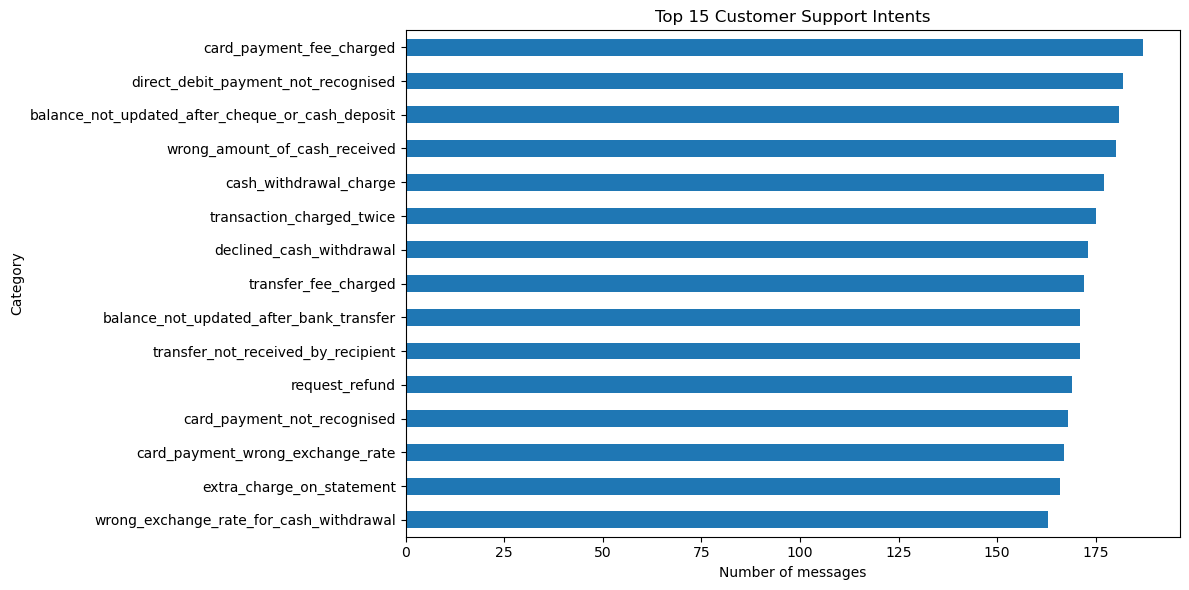

In [3]:
import matplotlib.pyplot as plt

category_counts = train_df["category"].value_counts()

print("Total categories:", len(category_counts))
print("\nTop 10 categories:")
print(category_counts.head(10))

print("\nBottom 10 categories:")
print(category_counts.tail(10))

# Visualize the 15 most common categories
plt.figure(figsize=(12, 6))

category_counts.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Customer Support Intents")
plt.xlabel("Number of messages")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

### 5 Initial Findings

The training dataset contains 10,003 customer messages across 77 intent categories, while the test dataset contains 3,080 messages.

No missing values were found during the initial inspection.

The category counts vary across the training set. `card_payment_fee_charged` is the most frequent category with 187 messages, while `contactless_not_working` is the least frequent with 35 messages.

This variation makes it important to evaluate the model using macro-F1 in addition to accuracy, so that performance across all intent categories is considered.

In [4]:
print("Duplicate training rows: ",train_df.duplicated().sum())
print("Duplicate test rows: ",test_df.duplicated().sum())
print("Repeating text messages:",train_df['text'].duplicated().sum())
train_texts = set(train_df['text'])
test_texts = set(test_df['text'])
print("Train_test Overlapping texts: ",train_texts.intersection(test_texts))

Duplicate training rows:  0
Duplicate test rows:  0
Repeating text messages: 0
Train_test Overlapping texts:  set()


## 6. Data Quality Checks

Missing values and duplicate records are checked before further analysis.

The initial inspection found no missing values in either column of the training dataset. The training and testing datasets also contain no duplicate rows or repeated messages within their respective files.

An overlap check was performed to identify identical message text appearing in both sets. No overlapping messages were found.

These checks provide confidence in the initial data quality, although they do not guarantee that every possible source of data leakage has been eliminated.

In [5]:
# Display 10 sample customer messages with their labels
for i in range(10):
    print("Text:", train_df.iloc[i]["text"])
    print("Category:", train_df.iloc[i]["category"])
    print("-" * 70)

Text: I am still waiting on my card?
Category: card_arrival
----------------------------------------------------------------------
Text: What can I do if my card still hasn't arrived after 2 weeks?
Category: card_arrival
----------------------------------------------------------------------
Text: I have been waiting over a week. Is the card still coming?
Category: card_arrival
----------------------------------------------------------------------
Text: Can I track my card while it is in the process of delivery?
Category: card_arrival
----------------------------------------------------------------------
Text: How do I know if I will get my card, or if it is lost?
Category: card_arrival
----------------------------------------------------------------------
Text: When did you send me my new card?
Category: card_arrival
----------------------------------------------------------------------
Text: Do you have info about the card on delivery?
Category: card_arrival
--------------------------

In [6]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

train_df["clean_text"] = train_df["text"].apply(clean_text)

print("Original text:")
print(train_df["text"].iloc[1])

print("\nCleaned text:")
print(train_df["clean_text"].iloc[1])

Original text:
What can I do if my card still hasn't arrived after 2 weeks?

Cleaned text:
what can i do if my card still hasn't arrived after 2 weeks?


In [7]:
import nltk
from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
text = train_df['text'].iloc[1].lower()
tokens =wordpunct_tokenize(text)
filtered_tokens = []
for i in tokens:
    if i.isalpha():
        if i not in stop_words:
            filtered_tokens.append(i)
print(filtered_tokens)

['card', 'still', 'arrived', 'weeks']


[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


## 7. Text Preprocessing

Text preprocessing prepares customer messages for feature extraction and model training.

The following techniques will be explored:

- Lowercasing text to normalize capitalization.
- Tokenization to split messages into individual tokens.
- Stop-word removal to investigate the effect of common words.
- Lemmatization and stemming to examine word normalization.

These techniques will be evaluated rather than assumed to improve performance. Words such as negations may carry important information about customer intent, so removing stop words indiscriminately can reduce useful context.

The final preprocessing pipeline will be selected based on experimental results.

In [8]:
import nltk
from nltk.stem import WordNetLemmatizer

nltk.download("wordnet")
nltk.download("omw-1.4")

lemmatizer = WordNetLemmatizer()

[nltk_data] Error loading wordnet: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading omw-1.4: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


In [9]:
lemmatized_tokens = []
for i in filtered_tokens:
    lemma=lemmatizer.lemmatize(i)
    lemmatized_tokens.append(lemma)
print("Before Lemmatization:",filtered_tokens)
print("After Lemmatization:",lemmatized_tokens)


Before Lemmatization: ['card', 'still', 'arrived', 'weeks']
After Lemmatization: ['card', 'still', 'arrived', 'week']


In [10]:
print("arrived:", lemmatizer.lemmatize("arrived", pos="v"))
print("running:", lemmatizer.lemmatize("running", pos="v"))
print("better:", lemmatizer.lemmatize("better", pos="a"))

arrived: arrive
running: run
better: good


### 8.1 Observations from Lemmatization

The WordNet Lemmatizer converts words into their base forms using a dictionary-based approach.

- By default, it treats words as nouns.
- Providing the correct part of speech can improve lemmatization.
- Lemmatization may reduce variations of words, but it does not always improve classification performance.
- In this project, its usefulness will be evaluated during model experimentation.

**Note:** The current examples demonstrate lemmatization on a single sample. A consistent preprocessing pipeline will be developed for the complete dataset later.

## 9. Stemming

Stemming is a text preprocessing technique that removes prefixes or suffixes from words to obtain their root form.

Unlike lemmatization, stemming does not always produce a valid dictionary word.

**Examples:**
- `playing` → `play`
- `studies` → `studi`
- `connected` → `connect`

In this project, stemming will be explored as another preprocessing technique for customer support ticket classification. Its results will later be compared with lemmatization.

In [11]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

In [12]:
stemmed_tokens = []

for i in filtered_tokens:
    stem = stemmer.stem(i)
    stemmed_tokens.append(stem)

print("Original tokens:", filtered_tokens)
print("Stemmed tokens:", stemmed_tokens)

Original tokens: ['card', 'still', 'arrived', 'weeks']
Stemmed tokens: ['card', 'still', 'arriv', 'week']


## 11. Stemming vs. Lemmatization

Stemming and lemmatization both reduce word variations, but they use different approaches.

| Aspect | Stemming | Lemmatization |
|---|---|---|
| Approach | Removes word endings using rules | Uses vocabulary and linguistic information |
| Output | May produce incomplete words | Generally produces meaningful base words |
| Example | `arrived` → `arriv` | `arrived` → `arrive` (when treated as a verb) |
| Speed | Generally faster | Can be slower |
| Linguistic accuracy | Less linguistically informed | More linguistically informed |

**Project decision:** We will evaluate different preprocessing approaches experimentally instead of assuming one is always better. For customer support messages, preserving meaningful words and negations can be especially important.

## 12. N-grams

N-grams are sequences of consecutive words or tokens in a text.

They help a model capture relationships between neighboring words rather than treating every word independently.

**Types of N-grams:**

- **Unigram:** A single word, e.g., `card`, `payment`
- **Bigram:** Two consecutive words, e.g., `card payment`
- **Trigram:** Three consecutive words, e.g., `card payment failed`

In customer support classification, phrases such as `cash withdrawal`, `direct debit`, and `cash withdrawal failed` may carry more meaning than individual words.

N-grams can be used with text vectorization methods such as CountVectorizer and TF-IDF.

In [13]:
from nltk.util import ngrams
from nltk.tokenize import wordpunct_tokenize

text = "my card payment failed"

tokens = wordpunct_tokenize(text.lower())

unigrams = list(ngrams(tokens, 1))
bigrams = list(ngrams(tokens, 2))
trigrams = list(ngrams(tokens, 3))

print("Unigrams:", unigrams)
print("Bigrams:", bigrams)
print("Trigrams:", trigrams)

Unigrams: [('my',), ('card',), ('payment',), ('failed',)]
Bigrams: [('my', 'card'), ('card', 'payment'), ('payment', 'failed')]
Trigrams: [('my', 'card', 'payment'), ('card', 'payment', 'failed')]


## 13. Bag of Words (BoW)

Bag of Words is a text representation technique that converts text into numerical features based on word occurrence or frequency.

A machine learning model cannot directly understand raw text, so we convert text into numbers.

BoW creates a vocabulary of unique words from the documents and represents each document using the counts of those words.

**Example documents:**

- Document 1: `I love banking`
- Document 2: `I love money`

Vocabulary: `I`, `love`, `banking`, `money`

| Document | I | love | banking | money |
|---|---:|---:|---:|---:|
| Document 1 | 1 | 1 | 1 | 0 |
| Document 2 | 1 | 1 | 0 | 1 |

**Limitation:** Basic BoW ignores word order and context. For example, `payment failed` and `failed payment` can have the same word counts.

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(ngram_range=(1, 1))

X_train_bow = bow_vectorizer.fit_transform(train_df["text"])
X_test_bow = bow_vectorizer.transform(test_df["text"])

print("Training matrix shape:", X_train_bow.shape)
print("Testing matrix shape:", X_test_bow.shape)

Training matrix shape: (10003, 2320)
Testing matrix shape: (3080, 2320)


## 14. TF-IDF (Term Frequency–Inverse Document Frequency)

TF-IDF is a text vectorization technique that converts text into numerical features while considering how important a word is within a document and across a collection of documents.

Unlike basic Bag of Words, which mainly counts word occurrences, TF-IDF reduces the relative importance of words that appear across many documents.

**Main components:**

- **Term Frequency (TF):** Measures how frequently a term appears in a document.
- **Inverse Document Frequency (IDF):** Reduces the weight of terms that appear in many documents.
- **TF-IDF:** Combines these components to assign a weight to each term.

**Example:** In customer support messages, a phrase such as `cash withdrawal` may help identify a particular intent. TF-IDF can represent the words numerically based on their distribution across messages.

**Limitation:** TF-IDF does not understand meaning or context like a human. It relies on statistical patterns in the text.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
doc = ["I love banking","I love money","banking helps people"]
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(doc)
print("Vocabulary:", tfidf_vectorizer.get_feature_names_out())
print("\nTF-IDF Matrix:\n", X_tfidf.toarray().round(2))


Vocabulary: ['banking' 'helps' 'love' 'money' 'people']

TF-IDF Matrix:
 [[0.71 0.   0.71 0.   0.  ]
 [0.   0.   0.61 0.8  0.  ]
 [0.47 0.62 0.   0.   0.62]]


In [16]:
print("Number of documents:", len(doc))
print("Documents:", doc)
print("TF-IDF matrix shape:", X_tfidf.shape)

Number of documents: 3
Documents: ['I love banking', 'I love money', 'banking helps people']
TF-IDF matrix shape: (3, 5)


## 15. Word Embeddings

Word embeddings are a text representation technique that converts words into dense numerical vectors. These vectors can capture semantic relationships between words based on patterns learned from text.

Machine learning models cannot directly understand words, so text must be represented numerically.

Unlike Bag of Words and TF-IDF, which create features based mainly on word occurrence and frequency, word embeddings can learn relationships between words.

**Example:**

Words such as `king` and `queen` may have related vector representations because they share certain semantic properties.

Similarly, in banking-related text, words such as `payment`, `transaction`, and `transfer` may have related representations if the training data captures those relationships.

**Advantages:**
- Can capture semantic similarities between words.
- Represent words as dense vectors.
- Can be useful for NLP tasks such as text classification and sentiment analysis.

**Limitations:**
- Quality depends on the training data and embedding method.
- Traditional word embeddings usually assign one vector to each word, even when the word has different meanings in different contexts.

**Common word embedding techniques:**
1. Word2Vec
2. GloVe
3. FastText

These techniques differ in how they learn vector representations from text.

In [17]:
import numpy as np

word_vectors = {
    "payment": np.array([0.8, 0.6, 0.2]),
    "transfer": np.array([0.7, 0.5, 0.3]),
    "banana": np.array([0.1, 0.9, 0.8])
}

print("Payment vector:", word_vectors["payment"])
print("Transfer vector:", word_vectors["transfer"])
print("Banana vector:", word_vectors["banana"])

Payment vector: [0.8 0.6 0.2]
Transfer vector: [0.7 0.5 0.3]
Banana vector: [0.1 0.9 0.8]


## 16. Word Similarity

Word similarity measures how similar two word vectors are in the vector space.

A common method is **Cosine Similarity**, which measures the cosine of the angle between two vectors.

- A value close to `1` indicates that the vectors point in a similar direction.
- A value close to `0` indicates little directional similarity.
- A value close to `-1` indicates opposite directions.

Cosine similarity is commonly used to compare word embeddings and other numerical text representations.

**Note:** Similarity scores are meaningful only in relation to the vectors being compared. Arbitrary vectors do not automatically represent real linguistic similarity.

In [18]:
from sklearn.metrics.pairwise import cosine_similarity

payment = word_vectors["payment"].reshape(1, -1)
transfer = word_vectors["transfer"].reshape(1, -1)
banana = word_vectors["banana"].reshape(1, -1)

print("Payment vs Transfer:",
      cosine_similarity(payment, transfer)[0][0].round(3))

print("Payment vs Banana:",
      cosine_similarity(payment, banana)[0][0].round(3))

Payment vs Transfer: 0.99
Payment vs Banana: 0.633


## 17. Word2Vec

Word2Vec is a word embedding technique that learns dense numerical representations of words from their surrounding context in a text corpus.

Words that appear in similar contexts can develop similar vector representations.

**Word2Vec has two main architectures:**

1. **CBOW (Continuous Bag of Words):** Predicts a target word using its surrounding context words.
2. **Skip-gram:** Predicts surrounding context words using a target word.

**Example:**

In the sentence `I need help with my bank transfer`, Word2Vec learns from relationships between words and their surrounding context.

**Applications:**
- Finding similar words
- Text classification
- Recommendation systems
- Other NLP tasks

**Limitation:** Word2Vec generally learns one vector per word, so it does not fully distinguish different meanings of the same word in different contexts.

In [19]:
%pip install gensim

Note: you may need to restart the kernel to use updated packages.


In [20]:
from gensim.models import Word2Vec

sentences = [
    ["bank", "transfer", "payment", "money"],
    ["payment", "card", "bank", "account"],
    ["money", "transfer", "bank", "account"],
    ["card", "payment", "transaction", "bank"],
    ["transfer", "money", "transaction", "payment"]
]

In [21]:
model = Word2Vec(
    sentences=sentences,
    vector_size=50,
    window=3,
    min_count=1,
    workers=1,
    sg=1,
    seed=42,
    epochs=100
)

In [22]:
print("Vector for 'payment':")
print(model.wv["payment"])

print("\nVector shape:")
print(model.wv["payment"].shape)

Vector for 'payment':
[-1.64861325e-02  1.10128848e-02  6.09562034e-03 -2.42693676e-03
 -2.66251760e-03  1.41910920e-02 -1.66173410e-02  7.86751229e-03
 -1.20465392e-02 -1.62432734e-02  1.22995651e-03  1.91536397e-02
  9.36756097e-03  1.05779162e-02  8.76563136e-03  1.14966985e-02
  5.59336622e-04 -1.50189791e-02  1.36246225e-02 -1.94717885e-03
 -7.78043322e-05 -5.42327901e-03 -1.27305845e-02  1.71926189e-02
  1.14495000e-02  5.69782313e-03 -3.94645007e-03  1.28531735e-02
  1.75300625e-03 -2.33144546e-03 -1.89766148e-03 -1.09756831e-02
 -1.64941791e-02  2.35180045e-03  1.55783258e-02 -1.73347145e-02
  1.43187623e-02  1.30696660e-02 -9.00505017e-03  5.40680019e-03
 -1.33896219e-02  1.03577366e-02  8.16143211e-03 -5.88102266e-03
 -1.71280894e-02  1.87352486e-02 -2.08400516e-03  1.58201791e-02
  7.09910877e-03  1.09657608e-02]

Vector shape:
(50,)


In [23]:
similar_words = model.wv.most_similar('payment',topn=3)
print("Words similar to 'payment':")
for word,score in similar_words:
    print(word,score)

Words similar to 'payment':
card 0.05080348998308182
money -0.01314780954271555
transaction -0.023339446634054184


### 18.1 Observations from Word2Vec

The Word2Vec model was trained on a small, manually prepared corpus using the Skip-gram architecture.

- Each word was represented by a 50-dimensional vector.
- The `most_similar()` method ranked words using cosine similarity.
- The results were weak because the training corpus was too small to learn reliable semantic relationships.

**Conclusion:** Word2Vec demonstrates how dense word representations can be learned from text. 

## 19. Part-of-Speech (POS) Tagging

Part-of-Speech tagging is an NLP technique that assigns a grammatical category to each word in a sentence.

Common categories include:

- **Noun (NN):** A person, place, thing, or concept.
- **Verb (VB):** An action or state.
- **Adjective (JJ):** Describes a noun.
- **Adverb (RB):** Modifies a verb, adjective, or another adverb.
- **Pronoun (PRP):** Replaces a noun.

**Example:**

Sentence: `The customer transferred money quickly.`

- `customer` → Noun
- `transferred` → Verb
- `money` → Noun
- `quickly` → Adverb

POS tagging can help identify the grammatical role of a word. It can also improve lemmatization when the correct part of speech is supplied.

In this project, POS tagging is a concept to understand; we will decide later whether it is useful in our final preprocessing pipeline.

In [24]:
import nltk

nltk.download("averaged_perceptron_tagger_eng")

sentence = "The customer transferred money quickly"

tokens = nltk.word_tokenize(sentence)

pos_tags = nltk.pos_tag(tokens)

print(pos_tags)

[nltk_data] Error loading averaged_perceptron_tagger_eng: <urlopen
[nltk_data]     error [Errno 11001] getaddrinfo failed>


[('The', 'DT'), ('customer', 'NN'), ('transferred', 'VBD'), ('money', 'NN'), ('quickly', 'RB')]


In [25]:
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("averaged_perceptron_tagger_eng")

[nltk_data] Error loading punkt: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading punkt_tab: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading averaged_perceptron_tagger_eng: <urlopen
[nltk_data]     error [Errno 11001] getaddrinfo failed>


False

In [26]:
sentence = "The customer transferred money quickly"

tokens = nltk.word_tokenize(sentence)
pos_tags = nltk.pos_tag(tokens)

print(pos_tags)

[('The', 'DT'), ('customer', 'NN'), ('transferred', 'VBD'), ('money', 'NN'), ('quickly', 'RB')]


In [27]:
word = "transferred"

print("Without POS:", lemmatizer.lemmatize(word))
print("With verb POS:", lemmatizer.lemmatize(word, pos="v"))

Without POS: transferred
With verb POS: transfer


### Observations: POS-Based Lemmatization

- Default lemmatization may treat a word as a noun, so `transferred` remains unchanged.
- When we specify the verb POS (`pos="v"`), `transferred` becomes `transfer`.
- POS tagging identifies the grammatical role of each word, which can improve lemmatization.
- POS-based lemmatization is more context-aware, but it requires additional processing.

**Conclusion:** POS-based lemmatization can help normalize words more accurately, although we should compare preprocessing methods on our actual dataset before choosing one for the final model.

## Named Entity Recognition (NER)

Named Entity Recognition (NER) is an NLP technique used to identify and classify named entities in text.

Common entity types include:

- **PERSON:** Names of people, such as Rahul.
- **ORGANIZATION:** Names of companies, such as Google.
- **LOCATION:** Places, such as Delhi.
- **DATE:** Dates or days, such as Monday.
- **MONEY:** Monetary values, such as ₹5,000.

**Example:**

"I transferred ₹5,000 to Rahul on Monday."

NER may identify `₹5,000` as MONEY, `Rahul` as PERSON, and `Monday` as DATE.

### NER vs POS Tagging

- **POS Tagging:** Identifies the grammatical role of each word, such as noun, verb, or adjective.
- **NER:** Identifies entities such as people, organizations, and locations.

### Applications in Our Project

In our Smart Customer Support Ticket Intelligence System, NER could help identify useful information such as banks, monetary amounts, dates, or transaction references mentioned in customer messages.

However, NER is not required for classifying tickets into BANKING77 categories. We will evaluate its usefulness before adding it to our final pipeline.

In [28]:
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('maxent_ne_chunker_tab')
nltk.download('words')
sentence = "The customer contacted HSBC in London on Monday."
tokens = word_tokenize(sentence)
pos_tags = nltk.pos_tag(tokens)
named_entities=nltk.ne_chunk(pos_tags)
print(named_entities)
for subtree in named_entities:
    if isinstance(subtree,nltk.Tree):
        entity=" ".join(word for word,tag in subtree.leaves())
        entity_type=subtree.label()
        print("Entity:",entity)
        print("Entity type:",entity_type)
        print()

[nltk_data] Error loading punkt_tab: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading averaged_perceptron_tagger_eng: <urlopen
[nltk_data]     error [Errno 11001] getaddrinfo failed>
[nltk_data] Error loading maxent_ne_chunker_tab: <urlopen error [Errno
[nltk_data]     11001] getaddrinfo failed>
[nltk_data] Error loading words: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


LookupError: 
**********************************************************************
  Resource [93mmaxent_ne_chunker_tab[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('maxent_ne_chunker_tab')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mchunkers/maxent_ne_chunker_tab/english_ace_multiclass/[0m

  Searched in:
    - 'C:\\Users\\krish/nltk_data'
    - 'c:\\Users\\krish\\anaconda3\\nltk_data'
    - 'c:\\Users\\krish\\anaconda3\\share\\nltk_data'
    - 'c:\\Users\\krish\\anaconda3\\lib\\nltk_data'
    - 'C:\\Users\\krish\\AppData\\Roaming\\nltk_data'
    - 'C:\\nltk_data'
    - 'D:\\nltk_data'
    - 'E:\\nltk_data'
**********************************************************************
